# **TP2 : Modèles Génératifs avec PyTorch sur MNIST**
### **Première Partie : Modèle Discriminatif & Auto-encodeur Simple (AE)**
**Basé sur les travaux pratiques du Pr. Mohamed YOUSSFI**

---
### **Objectifs de cette première partie :**
1. **Environnement & Jeu de données :** Configuration de l'environnement Python avec UV, chargement et exploration du dataset MNIST.
2. **Modèle Discriminatif :** Implémentation, entraînement et évaluation d'un classifieur de chiffres manuscrits (apprentissage de $P(y|x)$).
3. **Auto-encodeur Simple (AE) :** Conception, entraînement et exploration d'un auto-encodeur avec un espace latent 2D (reconstruction, réduction de dimension et analyse des limites génératives).


## **0. Préparation de l'environnement**
Vérification de la version de PyTorch et détection automatique du matériel disponible (GPU CUDA ou CPU).


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch Version :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé   :", device)


PyTorch Version : 2.14.1+cpu
Device utilisé   : cpu


## **1. Jeu de données MNIST**
Le jeu de données **MNIST** (*Modified National Institute of Standards and Technology*) contient des images de chiffres manuscrits en niveaux de gris de taille :
$$28 \times 28 = 784 \text{ pixels}$$

Chaque image possède un label entier compris entre **0 et 9**.
Nous utiliserons ce dataset pour comparer plusieurs paradigmes d'apprentissage.


In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Taille Train :", len(train_dataset))
print("Taille Test  :", len(test_dataset))


Taille Train : 60000
Taille Test  : 10000


### **Visualisation d'un lot d'images MNIST**
Observons les 10 premières images du premier lot avec leurs labels associés.


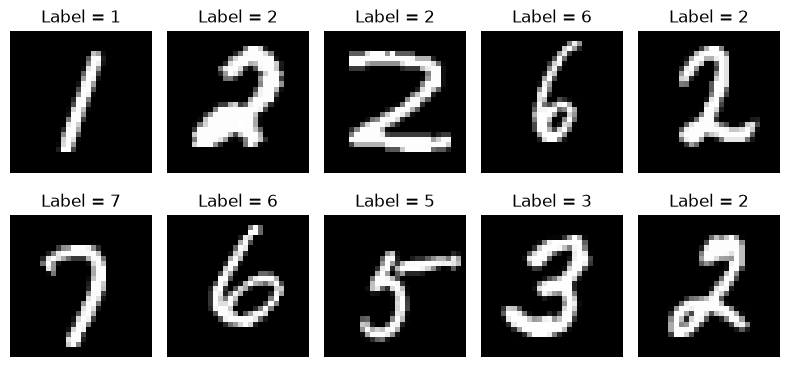

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()


---
# **Partie I — Modèle discriminatif**

## **2. Classification : Apprendre $P(y|x)$**

Un classifieur reçoit en entrée une image $x$ aplatie ($784$ dimensions) et prédit la distribution de probabilité des classes $y$ :
$$x \longrightarrow \text{Réseau de neurones} \longrightarrow \hat{y}$$

L'objectif est d'approximer la loi conditionnelle :
$$P(y|x)$$

Nous définissons un réseau entièrement connecté (*Multi-Layer Perceptron*) simple.


In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
print(classifier)


Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### **Fonction de perte & Optimiseur**
Pour une classification multi-classes, nous utilisons la perte d'entropie croisée (*Cross-Entropy Loss*) :
$$\mathcal{L}_{\text{class}} = \text{CrossEntropy}(\hat{y}, y)$$

Le label $y$ est indispensable pour guider l'apprentissage supervisé.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(loader)
        print(f"Epoch {epoch+1}/{epochs} - Loss = {avg_loss:.4f}")

train_classifier(classifier, train_loader, epochs=3)


Epoch 1/3 - Loss = 0.4120


Epoch 2/3 - Loss = 0.1892


Epoch 3/3 - Loss = 0.1377


### **Évaluation du modèle discriminatif**
Nous mesurons l'exactitude (*Accuracy*) sur le jeu de test indépendant.


In [6]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy (Méthode manuelle) = {100 * accuracy:.2f}%")


Accuracy (Méthode manuelle) = 96.35%


### **Évaluation avec TorchEval (`torcheval.metrics`)**
Comme vu dans le cours du professeur, nous pouvons également utiliser la bibliothèque `torcheval` pour un calcul modulaire et optimisé des métriques.


In [7]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier_torcheval(model, loader):
    model.eval()
    dev = next(model.parameters()).device

    metric = MulticlassAccuracy(device=dev)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()

acc_torcheval = evaluate_classifier_torcheval(classifier, test_loader)
print(f"Accuracy (Torcheval) = {100 * acc_torcheval:.2f}%")


C:\Users\user\TP2 IA GEN\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy (Torcheval) = 96.35%


### **Bilan du modèle discriminatif :**
Le réseau apprend la correspondance directe :
$$x \implies y$$

- Il **discrimine** efficacement les classes (taux de réussite $> 96\%$).
- Cependant, il est **incapable de générer** une nouvelle image de chiffre. Il ne connaît pas la distribution sous-jacente des données $P(x)$.


---
# **Partie II — Autoencodeur**

## **3. Idée générale & Architecture**
Un auto-encodeur apprend à reconstruire sa propre entrée de manière non supervisée :
$$x \longrightarrow \text{Encoder} \longrightarrow z \longrightarrow \text{Decoder} \longrightarrow \hat{x}$$
avec $\hat{x} \approx x$.

- Le vecteur $z$ est une **représentation latente** compacte de l'entrée.
- L'apprentissage devient : $x \to x$ (auto-supervisé, aucun label nécessaire).

Nous choisissons volontairement un espace latent en dimension 2 (`latent_dim = 2`) afin de pouvoir visualiser l'espace dans le plan 2D.


In [8]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        # Encodeur : compresse 784 -> 128 -> 32 -> latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        # Décodeur : reconstruit latent_dim -> 32 -> 128 -> 784 -> Sigmoid (pixels entre 0 et 1)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
print(ae)


Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


## **4. Perte de reconstruction**
L'erreur de reconstruction est mesurée par l'erreur quadratique moyenne (*Mean Squared Error*, MSE) :
$$\mathcal{L}_{\text{rec}} = \frac{1}{N} \sum_{i=1}^N (x_i - \hat{x}_i)^2$$


In [9]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(loader)
        print(f"Epoch {epoch+1}/{epochs} - Reconstruction Loss = {avg_loss:.4f}")

train_autoencoder(ae, train_loader, epochs=5)


Epoch 1/5 - Reconstruction Loss = 0.0651


Epoch 2/5 - Reconstruction Loss = 0.0515


Epoch 3/5 - Reconstruction Loss = 0.0478


Epoch 4/5 - Reconstruction Loss = 0.0457


Epoch 5/5 - Reconstruction Loss = 0.0442


## **5. Visualisation des reconstructions**
Comparons les images réelles (première ligne) et leurs reconstructions après passage dans le goulot d'étranglement 2D (deuxième ligne).


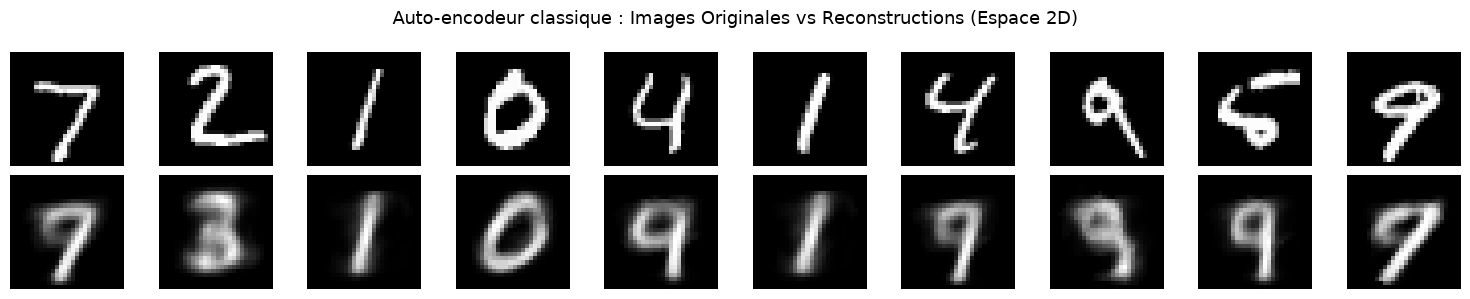

In [10]:
ae.eval()

x_sample, _ = next(iter(test_loader))
x_sample = x_sample[:10].to(device)

with torch.no_grad():
    x_hat = ae(x_sample)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x_sample[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstruit", fontsize=12)

plt.suptitle("Auto-encodeur classique : Images Originales vs Reconstructions (Espace 2D)", fontsize=13)
plt.tight_layout()
plt.show()


## **6. Visualisation de l'espace latent 2D**
Comme `latent_dim = 2`, chaque image de test est projetée en un point $(z_1, z_2)$.
Colorons ces points en fonction du label réel du chiffre pour observer l'organisation de l'espace latent.


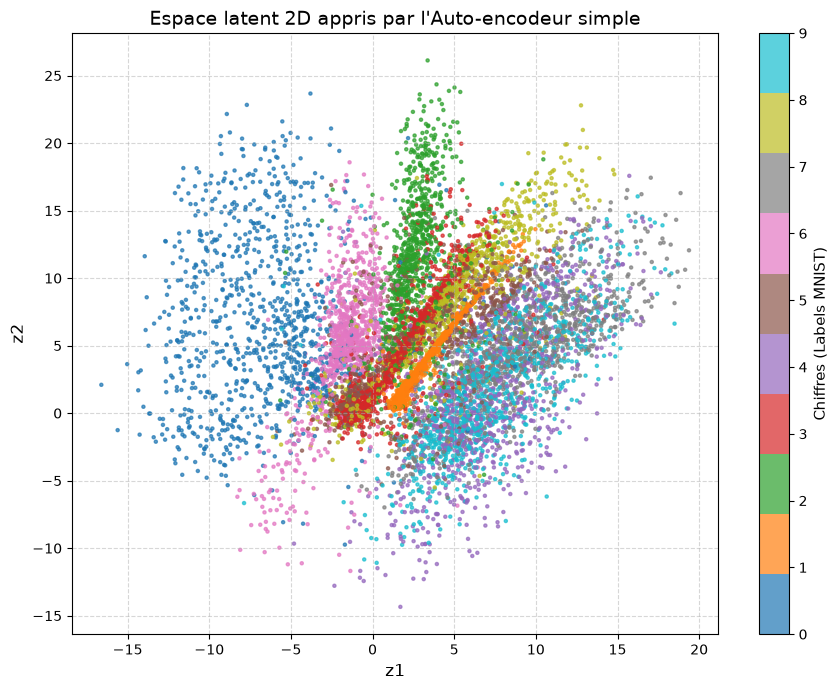

In [11]:
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(9, 7))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=5, cmap="tab10", alpha=0.7)
plt.xlabel("z1", fontsize=12)
plt.ylabel("z2", fontsize=12)
plt.title("Espace latent 2D appris par l'Auto-encodeur simple", fontsize=14)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label("Chiffres (Labels MNIST)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## **7. Génération à partir d'un chiffre connu**
En calculant le centre de gravité (barycentre latent) de toutes les images d'un chiffre donné dans l'espace latent, nous pouvons le passer au décodeur pour obtenir le représentant prototypique de ce chiffre.


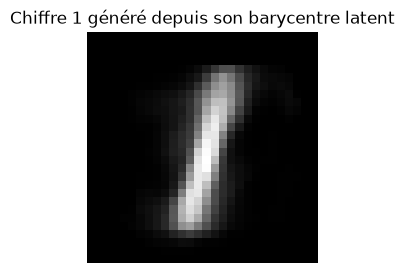

In [12]:
@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    dev = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        images_c = images[labels == chiffre]

        if images_c.shape[0] == 0:
            continue

        z = model.encode(images_c.to(dev))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

# Génération et affichage du prototype pour le chiffre 1 (comme dans le code du professeur)
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.figure(figsize=(3, 3))
plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.title("Chiffre 1 généré depuis son barycentre latent")
plt.axis("off")
plt.show()


## **8. Limite d'un auto-encodeur classique & Motivation pour le VAE**
L'auto-encodeur classique apprend une excellente compression et reconstruction, mais son espace latent souffre de limitations fondamentales pour la génération :

1. **Absence de continuité globale :** L'espace latent contient des "trous" (zones vides sans données d'entraînement).
2. **Distribution inconnue et non bornée :** Les points $z$ ne suivent pas une loi de probabilité standard (comme une loi gaussienne normale).
3. **Impossibilité d'échantillonnage aléatoire :** Si l'on tire un vecteur aléatoire $z \sim \mathcal{N}(0, I)$ au hasard, le décodeur produit souvent un bruit flou ou incohérent.

> **Conclusion :** Pour transformer l'auto-encodeur en un **véritable modèle génératif probabiliste**, nous devons forcer l'espace latent à suivre une distribution connue continue et régulière.
> C'est l'objectif du **Variational Autoencoder (VAE)**, développé dans le notebook séparé (`TP2_Partie2_VAE.ipynb`).
